# 02. 멤버를 골라 섞기 — greedy ensemble selection

[01 추론의 흐름](01_inference_evolution.ipynb)의 기본 앙상블은 멤버 n개를 같은 가중치로 평균합니다. 추론에 연산을 더 쓸 수 있다면, 후보를 훨씬 많이 만들어 두고 학습 행 안에서 잘 맞는 조합을 골라 섞을 수 있습니다. Caruana et al.(2004)의 ensemble selection이고, *Test-Time Compute for Tabular Foundation Models*(arXiv 2610.12005)가 이것을 TabPFN-3에 써서 TabArena 51개 데이터셋에서 기본 예측보다 오차를 2.44% 줄였다고 보고했습니다. 이 저장소의 구현은 `minipfn/inference/ensemble_selection.py`의 `GreedyEnsembleClassifier`·`GreedyEnsembleRegressor`입니다(issue #43).

다루는 흐름:

1. 손으로 해 보는 greedy 선택
2. 후보 pool — 멤버 × softmax 온도
3. 왜 out-of-fold 예측으로 고르나
4. 실제 데이터셋에서 돌려 보기
5. 큰 benchmark에서는
6. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_inference/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 3·4절은 Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다. 4절은 CPU에서 3분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

from minipfn import TabPFNv2Classifier, set_seed
from minipfn.inference import ensemble_selection as es

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 손으로 해 보는 greedy 선택

예보관 세 명이 닷새 동안 날씨를 예보했습니다. 표의 값은 예보관이 **실제로 일어난 날씨**에 준 확률입니다. 1~4일은 맑았고 5일째에 비가 왔습니다. A는 맑은 날을 자신 있게 맞히지만 5일째 비를 놓쳤고, B는 매일 0.6으로 무난하게 말하고, C는 맑은 날에는 덜 자신 있지만 5일째 비를 맞혔습니다.

분류의 손실은 log loss, 곧 정답에 준 확률의 $-\log$ 평균입니다. 확률을 평균한 예측도 정답에 준 확률의 평균이므로, 이 표만 있으면 어떤 조합의 손실이든 계산할 수 있습니다.

In [3]:
forecasts = pd.DataFrame(
    [
        [0.95, 0.95, 0.95, 0.95, 0.10],  # A: 맑은 날은 자신 있게, 비는 놓침
        [0.60, 0.60, 0.60, 0.60, 0.60],  # B: 매일 무난하게
        [0.55, 0.55, 0.55, 0.55, 0.95],  # C: 맑은 날은 덜 자신 있게, 비는 맞힘
    ],
    index=["A", "B", "C"],
    columns=["1일 (맑음)", "2일 (맑음)", "3일 (맑음)", "4일 (맑음)", "5일 (비)"],
)
probs = forecasts.to_numpy()
forecasts["log loss"] = es._log_loss(probs)  # 행마다 -log(정답 확률)의 평균
display(forecasts.round(3))

,1일 (맑음),2일 (맑음),3일 (맑음),4일 (맑음),5일 (비),log loss
A,0.95,0.95,0.95,0.95,0.10,0.502
B,0.60,0.60,0.60,0.60,0.60,0.511
C,0.55,0.55,0.55,0.55,0.95,0.489


혼자서는 C가 가장 낫고(0.489), A와 B는 비슷합니다. greedy 선택은 빈 바구니에서 시작해, 라운드마다 "지금 바구니의 평균에 이 후보를 하나 더 넣으면 손실이 얼마가 되나"를 후보마다 계산하고 가장 작은 것을 넣습니다. 이미 넣은 후보를 또 넣어도 됩니다. 5라운드를 따라가 봅니다.

In [4]:
basket_sum = np.zeros(probs.shape[1])  # 바구니에 넣은 예측의 합
basket = []
rounds = []
for t in range(5):
    # 후보마다: 바구니에 하나 더 넣었을 때의 평균 예측과 그 손실
    tried = (basket_sum + probs) / (t + 1)
    losses = es._log_loss(tried)
    pick = int(np.argmin(losses))
    basket_sum += probs[pick]
    basket.append("ABC"[pick])
    rounds.append(
        {
            "라운드": t + 1,
            "A를 넣으면": losses[0],
            "B를 넣으면": losses[1],
            "C를 넣으면": losses[2],
            "고른 것": "ABC"[pick],
            "바구니": "".join(basket),
        }
    )
display(pd.DataFrame(rounds).set_index("라운드").round(3))

weights = es.greedy_weights(probs, es._log_loss, n_rounds=5)  # 저장소의 함수
print("가중치 (고른 횟수 / 5):", dict(zip("ABC", weights, strict=True)))
print(f"greedy 조합의 log loss: {es._log_loss((weights @ probs)[None])[0]:.3f}")
print(f"세 명 균일 평균의 log loss: {es._log_loss(probs.mean(0)[None])[0]:.3f}")

,A를 넣으면,B를 넣으면,C를 넣으면,고른 것,바구니
라운드,,,,,
1,0.502,0.511,0.489,C,C
2,0.359,0.494,0.489,A,CA
3,0.354,0.405,0.386,A,CAA
4,0.363,0.382,0.359,C,CAAC
5,0.353,0.386,0.373,A,CAACA


가중치 (고른 횟수 / 5): {'A': np.float64(0.6), 'B': np.float64(0.0), 'C': np.float64(0.4)}
greedy 조합의 log loss: 0.353
세 명 균일 평균의 log loss: 0.405


1라운드는 혼자 가장 좋은 C를 넣습니다. 2라운드에는 둘째로 좋은 B가 아니라 A를 넣습니다. C가 약한 맑은 날을 A가 채워 주기 때문입니다. 그 뒤로는 A와 C를 번갈아 넣어 가중치가 A 0.6, C 0.4가 되고, 손실은 0.353으로 누구 혼자보다도, 세 명을 똑같이 섞은 것(0.405)보다도 낮습니다. B는 한 번도 들어가지 않았습니다. 혼자서 나쁘지 않아도 이미 있는 것과 겹치면 뽑히지 않습니다.

`es.greedy_weights`가 이 계산을 그대로 합니다. 저장소는 라운드 40번을 돌고(TabArena·AutoGluon과 논문의 기본값), 일찍 멈추지 않으며, 동점이면 앞 번호를 고릅니다.

## 2. 후보 pool — 멤버 × softmax 온도

TabPFN에서 후보 하나는 **멤버 하나와 softmax 온도 하나의 조합**입니다. 논문은 멤버 8개짜리 앙상블 설정 96개를 후보로 썼지만, 그 설정은 TabPFN-3 전처리 옵션이라 그대로 옮길 수 없어서 이 저장소가 정했습니다.

- **멤버 24개**(`POOL_SIZE`): 앞의 `n_estimators`개는 기본 앙상블과 똑같은 멤버이고, 나머지는 무작위로 뽑습니다. 전처리 종류(quantile, power, robust), 이상값을 자르는 σ(3, 6, 12), one-hot 여부, feature 순서·클래스 번호를 정하는 seed를 뽑습니다.
- **온도 9개**(`TEMPERATURES`): 0.25~1.5. 온도와 σ의 후보는 TabArena의 TabPFN-2.5 search space에서 가져왔습니다.
- **후보 0번**: 기본 앙상블 그대로(기본 멤버를 기본 온도 0.9로 균일 평균). greedy가 "기본이 제일 낫다"고 고를 수 있게 넣습니다.

그래서 후보는 1 + 24 × 9 = 217개입니다. 온도는 멤버가 낸 logit을 나누기만 하므로 forward를 더 하지 않습니다. 멤버 하나가 낸 logit 하나로 온도의 효과를 봅니다.

In [5]:
logits = torch.tensor([2.0, 0.5, -1.0])  # 클래스 3개에 대한 한 행의 logit
temperature_rows = {}
for t in es.TEMPERATURES:
    p = torch.softmax(logits / t, dim=-1)
    temperature_rows[t] = {f"클래스 {k}": p[k].item() for k in range(3)}
temperature_table = pd.DataFrame(temperature_rows).T
temperature_table.index.name = "온도"
display(temperature_table.round(3))
print("후보 수:", 1 + es.POOL_SIZE * len(es.TEMPERATURES))

,클래스 0,클래스 1,클래스 2
온도,,,
0.25,0.998,0.002,0.000
0.50,0.950,0.047,0.002
0.60,0.918,0.075,0.006
0.70,0.884,0.104,0.012
0.80,0.850,0.130,0.020
0.90,0.817,0.154,0.029
1.00,0.786,0.175,0.039
1.25,0.718,0.216,0.065
1.50,0.665,0.245,0.090


후보 수: 217


온도가 1보다 작으면 확률이 가장 큰 클래스로 몰리고(0.25에서 0.998), 1보다 크면 고르게 퍼집니다. 같은 멤버라도 온도를 바꾸면 "얼마나 자신 있게 말할지"만 다른 후보가 됩니다. 1절의 A가 낮은 온도, B가 높은 온도에 해당한다고 볼 수 있습니다.

pool의 멤버 24개는 이렇게 생겼습니다. pool을 만드는 `_pool`은 내부 함수라 여기서만 꺼내 봅니다.

In [6]:
model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier
selector = es.GreedyEnsembleClassifier(model, n_estimators=4)
rng = np.random.default_rng(selector.random_state)
n_classes = 3
default_members = selector._default_members(rng, n_classes)  # 기본 앙상블의 멤버 4개
pool = selector._pool(rng, default_members, n_classes)  # 그 뒤에 무작위 멤버 20개

pool_table = pd.DataFrame(
    [
        {
            "출처": "기본" if i < len(default_members) else "무작위",
            "전처리": m.kind,
            "자르는 σ": m.outlier_sigma,
            "one-hot": m.one_hot,
            "seed": m.seed,
        }
        for i, m in enumerate(pool)
    ]
)
display(pool_table.head(8))
print(pool_table.groupby("출처")["전처리"].value_counts().to_dict())

,출처,전처리,자르는 σ,one-hot,seed
0,기본,quantile,12.0,True,661058651
1,기본,power,12.0,True,35492826
2,기본,quantile,12.0,True,1960127675
3,기본,power,12.0,True,1566581934
4,무작위,power,12.0,True,595598245
5,무작위,quantile,12.0,False,1190382222
6,무작위,robust,3.0,True,191741830
7,무작위,power,6.0,False,1033071480


{('기본', 'quantile'): 2, ('기본', 'power'): 2, ('무작위', 'power'): 8, ('무작위', 'robust'): 7, ('무작위', 'quantile'): 5}


## 3. 왜 out-of-fold 예측으로 고르나

1절에서는 정답을 알고 골랐습니다. 실제로는 test 행의 정답을 모르니 학습 행으로 골라야 합니다. 그런데 TabPFN은 학습 행을 context로 넣고 예측하므로, 학습 행을 그대로 예측하면 정답을 보고 맞히는 셈이 됩니다. wine 데이터(178행, 3클래스)의 절반을 학습 행으로 써서, 같은 기본 앙상블의 log loss를 세 가지 방법으로 잽니다.

In [7]:
x_wine, y_wine = load_wine(return_X_y=True)
x_tr, x_te, y_tr, y_te = train_test_split(
    x_wine, y_wine, test_size=0.5, random_state=0, stratify=y_wine
)

clf = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr)
in_sample = log_loss(y_tr, clf.predict_proba(x_tr))  # context에 있는 행을 그대로 예측
test = log_loss(y_te, clf.predict_proba(x_te))

# out-of-fold: 학습 행을 8묶음으로 나눠, 묶음마다 나머지 7묶음만 context로 두고 예측한다
oof_proba = np.zeros((len(y_tr), 3))
folds = StratifiedKFold(es.N_FOLDS, shuffle=True, random_state=0)
for fit_rows, held_out_rows in folds.split(x_tr, y_tr):
    fold_clf = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr[fit_rows], y_tr[fit_rows])
    oof_proba[held_out_rows] = fold_clf.predict_proba(x_tr[held_out_rows])
oof = log_loss(y_tr, oof_proba)

display(
    pd.DataFrame(
        {"log loss": [in_sample, oof, test]},
        index=["학습 행 그대로 (context에 있음)", "학습 행 out-of-fold (8-fold)", "test 행"],
    ).round(4)
)

,log loss
학습 행 그대로 (context에 있음),0.0021
학습 행 out-of-fold (8-fold),0.0534
test 행,0.0512


학습 행을 그대로 예측하면 손실이 test보다 훨씬 작습니다. 이 값으로 고르면 "가장 자신 있게 말하는 후보"가 늘 이깁니다. out-of-fold 예측은 각 행을 그 행이 빠진 context로 예측하므로 test와 같은 조건이 됩니다. `GreedyEnsembleClassifier`는 후보 217개 모두의 out-of-fold 예측을 이렇게 만들고(fold마다 멤버 전처리도 그 fold의 학습 행으로 다시 맞춥니다), 그 위에서 1절의 greedy를 돌립니다. 고른 뒤에는 가중치가 있는 멤버만 학습 행 전체로 다시 맞춰 test를 예측합니다.

비용도 여기서 나옵니다. 멤버 24개 × fold 8개 = 192번 맞추고 예측해야 하므로, 기본 앙상블(멤버 4개)보다 맞추는 시간이 몇십 배 깁니다. test를 예측하는 시간은 고른 멤버 수만큼만 듭니다.

## 4. 실제 데이터셋에서 돌려 보기

wine(학습 행 89개)의 split 3개와 breast cancer(569행, feature 30개, 학습 행 284개)의 split 2개에서 기본 앙상블과 비교합니다. wine에서는 논문이 견준 두 방법도 함께 봅니다. `best`는 out-of-fold 손실이 가장 작은 후보 하나만 쓰고, `uniform`은 후보 0번을 뺀 216개를 같은 가중치로 평균합니다. 여기서는 논문 방식 그대로 보려고 저장소가 기본으로 켜 두는 안전장치를 끕니다(`min_improvement=0`). 안전장치는 [03](03_greedy_guard.ipynb)에서 봅니다.

In [8]:
x_bc, y_bc = load_breast_cancer(return_X_y=True)
runs = [("wine", x_wine, y_wine, s, ["greedy", "best", "uniform"]) for s in range(3)]
runs += [("breast cancer", x_bc, y_bc, s, ["greedy"]) for s in range(2)]

rows = []
chosen = []
for data_name, x, y, split, selections in runs:
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.5, random_state=split, stratify=y)
    start = time.perf_counter()
    default_proba = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr).predict_proba(x_te)
    rows.append(
        {
            "데이터": data_name,
            "split": split,
            "방법": "default",
            "test log loss": log_loss(y_te, default_proba),
            "초": time.perf_counter() - start,
        }
    )
    for selection in selections:
        start = time.perf_counter()
        sel = es.GreedyEnsembleClassifier(
            model, n_estimators=4, selection=selection, min_improvement=0.0
        )
        proba = sel.fit(x_tr, y_tr).predict_proba(x_te)
        info = sel.selection_
        rows.append(
            {
                "데이터": data_name,
                "split": split,
                "방법": selection,
                "test log loss": log_loss(y_te, proba),
                "초": time.perf_counter() - start,
                "OOF (기본)": info["oof_loss_default"],
                "OOF (고른 것)": info["oof_loss_selected"],
                "쓴 멤버": info["used_members"],
            }
        )
        if selection == "greedy":
            # 온도마다 가중치의 합
            by_temperature = {}
            for member in sel.member_weights_:
                for t, w in member.items():
                    by_temperature[t] = by_temperature.get(t, 0.0) + w
            chosen.append({"데이터": data_name, "split": split, **by_temperature})

results = pd.DataFrame(rows)
display(results.set_index(["데이터", "split", "방법"]).round(4))

test log loss        초  OOF (기본)  OOF (고른 것)  \
데이터           split 방법                                                      
wine          0     default         0.0512   0.3518       NaN         NaN   
                    greedy          0.1529  10.6630    0.0534      0.0131   
                    best            0.1642  10.7671    0.0534      0.0131   
                    uniform         0.0596  14.3621    0.0534      0.0548   
              1     default         0.0601   0.5258       NaN         NaN   
                    greedy          0.0574  11.1514    0.0729      0.0531   
                    best            0.0790  11.4294    0.0729      0.0598   
                    uniform         0.0638  11.5343    0.0729      0.0790   
              2     default         0.0259   0.2859       NaN         NaN   
                    greedy          0.0166   9.0372    0.0925      0.0631   
                    best            0.0323   9.0328    0.0925      0.0711   
                    uniform         0.0292  10.7358    0.0925      0.0973   
breast cancer 0     default         0.0624   1.9724       NaN         NaN   
                    greedy          0.0635  49.7627    0.0919      0.0800   
              1     default         0.0895   2.4001       NaN         NaN   
                    greedy          0.1017  52.5979    0.0489      0.0330   

                             쓴 멤버  
데이터           split 방법             
wine          0     default   NaN  
                    greedy    2.0  
                    best      1.0  
                    uniform  24.0  
              1     default   NaN  
                    greedy    2.0  
                    best      1.0  
                    uniform  24.0  
              2     default   NaN  
                    greedy    3.0  
                    best      1.0  
                    uniform  24.0  
breast cancer 0     default   NaN  
                    greedy    6.0  
              1     default   NaN  
                    greedy    4.0

greedy는 wine split 1·2에서 기본보다 낮았지만(0.060 → 0.057, 0.026 → 0.017), wine split 0에서는 세 배 가까이 나빠졌고(0.051 → 0.153) breast cancer 두 split에서도 조금 나빠졌습니다. 그런데 out-of-fold 손실은 다섯 split 모두 기본보다 줄었습니다. 기본 앙상블이 후보 0번으로 들어 있으니, out-of-fold 위에서는 greedy가 기본보다 나쁜 조합을 고를 일이 거의 없습니다. 문제는 그 이득이 test로 이어지느냐입니다.

`best`는 후보 하나에 모두 걸어서 세 split 모두 greedy보다 나쁩니다. `uniform`은 out-of-fold에서도 test에서도 기본보다 조금 나쁩니다. 논문(TabArena 51개)에서도 `uniform`은 기본보다 오차가 3.68% 컸습니다. 아무렇게나 만든 멤버를 다 섞으면 기본 멤버보다 못한 멤버가 섞여 들어가기 때문입니다. 맞추는 시간은 wine에서 0.4초가 10초쯤으로, breast cancer에서 2초가 50초쯤으로 늘었습니다.

greedy가 고른 후보를 온도마다 묶어 가중치를 더해 봅니다.

In [9]:
temperature_weights = pd.DataFrame(chosen).set_index(["데이터", "split"]).fillna(0.0)
temperature_weights = temperature_weights[sorted(temperature_weights.columns)]
temperature_weights.columns = [f"T={t}" for t in temperature_weights.columns]
display(temperature_weights.round(3))

T=0.25  T=0.6  T=0.7  T=0.8  T=0.9  T=1.0  T=1.25  T=1.5
데이터           split                                                          
wine          0       1.000  0.000    0.0  0.000   0.00  0.000   0.000   0.00
              1       0.600  0.025    0.0  0.025   0.35  0.000   0.000   0.00
              2       0.475  0.000    0.5  0.025   0.00  0.000   0.000   0.00
breast cancer 0       0.575  0.000    0.0  0.150   0.05  0.050   0.025   0.15
              1       0.725  0.000    0.0  0.025   0.00  0.025   0.225   0.00

다섯 split 모두 가중치의 절반 가까이 또는 그 이상이 가장 낮은 온도 0.25에 있고, 가장 크게 나빠진 wine split 0은 전부 0.25입니다. 학습 행이 89개뿐이고 기본 out-of-fold 손실이 이미 0.05쯤이라, 거의 다 맞히는 행에서 확률을 1에 더 붙이는 것이 out-of-fold에서는 이득으로 보입니다(wine split 0은 0.053 → 0.013). 하지만 test에서 확신한 채로 틀린 행이 하나라도 있으면 그 행의 손실이 크게 늘어납니다. 2절의 표처럼 온도 0.25는 0.8쯤이던 확률을 0.998로 만듭니다.

두 손실의 변화를 나란히 그려 봅니다.

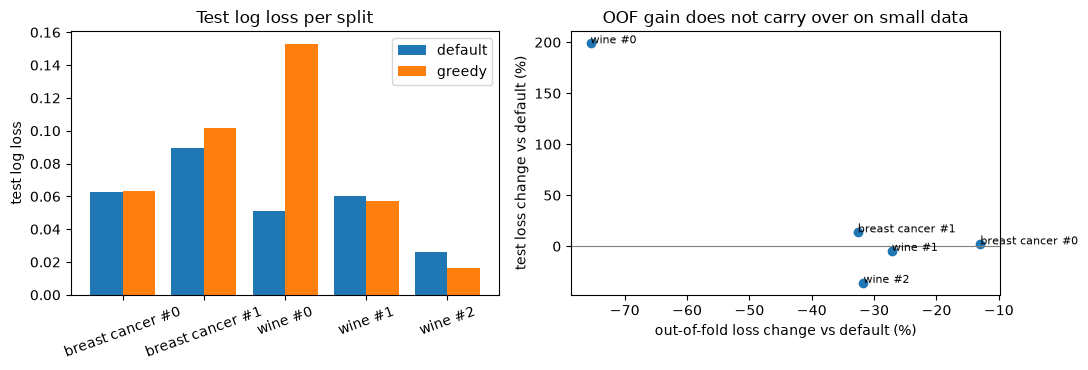

In [10]:
pairs = results[results["방법"].isin(["default", "greedy"])].copy()
pairs["label"] = pairs["데이터"] + " #" + pairs["split"].astype(str)
pivot = pairs.pivot_table(index="label", columns="방법", values="test log loss")
oof_gain = results[results["방법"] == "greedy"].copy()
oof_gain["label"] = oof_gain["데이터"] + " #" + oof_gain["split"].astype(str)
oof_gain = oof_gain.set_index("label")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x_pos = np.arange(len(pivot))
axes[0].bar(x_pos - 0.2, pivot["default"], 0.4, label="default")
axes[0].bar(x_pos + 0.2, pivot["greedy"], 0.4, label="greedy")
axes[0].set_xticks(x_pos, pivot.index, rotation=20)
axes[0].set_ylabel("test log loss")
axes[0].set_title("Test log loss per split")
axes[0].legend()

oof_change = oof_gain["OOF (고른 것)"] / oof_gain["OOF (기본)"] - 1
test_change = pivot.loc[oof_gain.index, "greedy"] / pivot.loc[oof_gain.index, "default"] - 1
axes[1].scatter(100 * oof_change, 100 * test_change)
for label in oof_gain.index:
    axes[1].annotate(label, (100 * oof_change[label], 100 * test_change[label]), fontsize=8)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel("out-of-fold loss change vs default (%)")
axes[1].set_ylabel("test loss change vs default (%)")
axes[1].set_title("OOF gain does not carry over on small data")
plt.tight_layout()
plt.show()

오른쪽 그림의 가로축(out-of-fold 손실 변화)은 다섯 split 모두 −13~−75%인데, 세로축(test 손실 변화)은 −36%에서 +199%까지 흩어져 있습니다. out-of-fold에서 가장 많이 줄인 wine split 0이 test에서는 가장 나쁩니다. 학습 행이 적으면 out-of-fold 손실 자체의 노이즈가 커서, 후보 217개 가운데 그 노이즈에 가장 잘 맞는 것을 고르게 됩니다. 후보가 많을수록 이 위험도 커집니다. 데이터셋이 많을 때 평균은 어떻게 되는지가 다음 절입니다.

## 5. 큰 benchmark에서는

데이터셋 다섯 개로는 방법의 평균적인 효과를 알 수 없습니다. 이 저장소는 v2 공개 가중치로 TabArena-Lite(51개 데이터셋)와 BeyondArena-lite(78개 split)에서 같은 방법을 쟀습니다(PR #49, 학습은 H100). Elo는 다른 모델들과 겨룬 점수이고, TabArena-Lite의 95% 신뢰구간은 ±60쯤입니다.

| | TabArena-Lite Elo | BeyondArena-lite Elo | 그 가운데 무작위 split | 그 가운데 grouped split |
|---|---|---|---|---|
| 기본 앙상블 | 1221 | 1028 | 1086 | 1080 |
| greedy (PR #49) | 1260 | 1029 | 1099~1118 | 1023 |

맞추는 시간은 데이터셋 하나에 1.1초에서 19~63초로 늘었고, 예측 시간은 거의 그대로였습니다. 논문(TabPFN-3, TabArena 51개)은 기본 대비 오차가 greedy −2.44%, `best` −1.25%, `uniform` +3.68%라고 보고했습니다.

TabArena-Lite처럼 test가 학습 행과 같은 분포에서 무작위로 뽑힌 경우에는 greedy가 이득입니다. 그러나 BeyondArena의 grouped split, 곧 같은 환자·같은 기계처럼 group 하나가 통째로 test에 가는 split에서는 손해였습니다. 가장 나빴던 곳은 mice_protein으로, 기본 앙상블의 out-of-fold 손실이 거의 0이라 greedy가 멤버 하나를 온도 0.25로 골랐고 test log loss가 1.14에서 4.8쯤으로 커졌습니다. 4절의 wine에서 본 것과 같은 실패입니다. 이를 막는 장치는 [03 greedy 선택의 안전장치](03_greedy_guard.ipynb)에서 봅니다.

## 6. 정리

| 단계 | 하는 일 | 저장소 |
|---|---|---|
| 후보 만들기 | 멤버 24개(기본 4 + 무작위 20) × 온도 9개 + 기본 앙상블 = 217개 | `POOL_SIZE`, `POOL_KINDS`, `TEMPERATURES`, `OUTLIER_SIGMAS` |
| 점수 매기기 | 후보마다 학습 행의 8-fold out-of-fold 예측 | `N_FOLDS`, `_out_of_fold` |
| 고르기 | 40라운드 동안 평균에 더했을 때 손실이 가장 작은 후보를 넣기(중복 허용) | `greedy_weights`, `N_ROUNDS` |
| 예측 | 가중치가 있는 멤버만 학습 행 전체로 다시 맞춰, 고른 온도와 가중치로 섞기 | `GreedyEnsembleClassifier.predict_proba` |

- greedy는 혼자 좋은 후보가 아니라 이미 고른 것을 보완하는 후보를 넣습니다(1절의 A).
- out-of-fold로 고르지 않으면 가장 자신 있게 말하는 후보가 이깁니다(3절).
- 학습 행이 적거나 기본 out-of-fold 손실이 이미 작으면, out-of-fold에서의 이득이 test로 이어지지 않고 낮은 온도를 골라 지나치게 확신할 수 있습니다(4절).
- 평가 명령: `scripts/tabpfn_v2/eval.py --test-time greedy`.